In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("../data/raw/train.csv")
features = pd.read_csv("../data/raw/features.csv")
stores = pd.read_csv("../data/raw/stores.csv")
test = pd.read_csv("../data/raw/test.csv")

train_clean = train.copy()
features_clean = features.copy()
test_clean = test.copy()
stores_clean = stores.copy()

train_clean["Date"] = pd.to_datetime(train_clean["Date"])
features_clean["Date"] = pd.to_datetime(features_clean["Date"])
test_clean["Date"] = pd.to_datetime(test_clean["Date"])

### 1. Calculate average and median weekly sales by holiday status

In [2]:
holiday_summary = (
    train_clean
    .groupby("IsHoliday")["Weekly_Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print(holiday_summary)

            count      mean   median       std
IsHoliday                                     
False      391909  15901.45  7589.95  22330.75
True        29661  17035.82  7947.74  27222.00


- Finding 1: Average sales are 7.1 % higher during holiday weeks.

- Finding 2: Sales vary more during holiday weeks.

- Finding 3: The mean is much higher than the median in both groups.

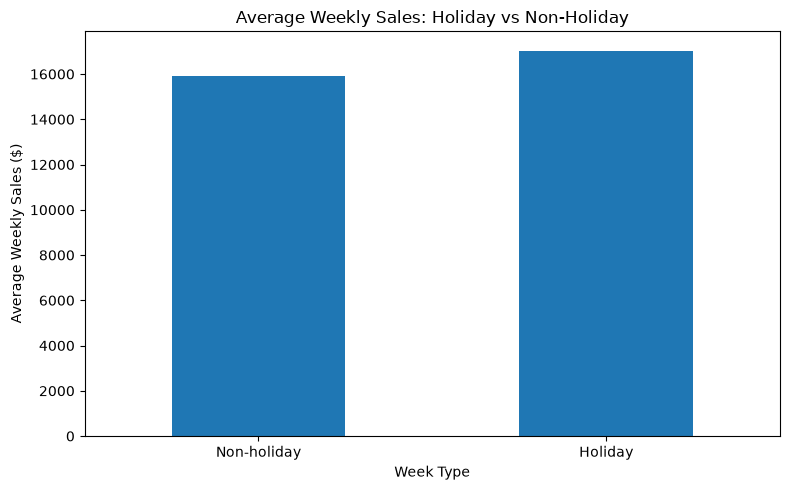

In [3]:
import matplotlib.pyplot as plt

# Calculate average sales for each holiday category
holiday_means = (
    train_clean
    .groupby("IsHoliday")["Weekly_Sales"]
    .mean()
)

# Give the categories readable labels
holiday_means.index = ["Non-holiday", "Holiday"]

# Create the bar chart
holiday_means.plot(kind="bar", figsize=(8, 5))

plt.title("Average Weekly Sales: Holiday vs Non-Holiday")
plt.xlabel("Week Type")
plt.ylabel("Average Weekly Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 2. Sales change over time

#### Aggregate sales by week

In [4]:
# Calculate total sales across all stores and departments for each week
weekly_sales = (
    train_clean
    .groupby("Date")["Weekly_Sales"]
    .sum()
    .sort_index()
)

print(weekly_sales.head())
print("\nNumber of weeks:", len(weekly_sales))

Date
2010-02-05    49750740.50
2010-02-12    48336677.63
2010-02-19    48276993.78
2010-02-26    43968571.13
2010-03-05    46871470.30
Name: Weekly_Sales, dtype: float64

Number of weeks: 143


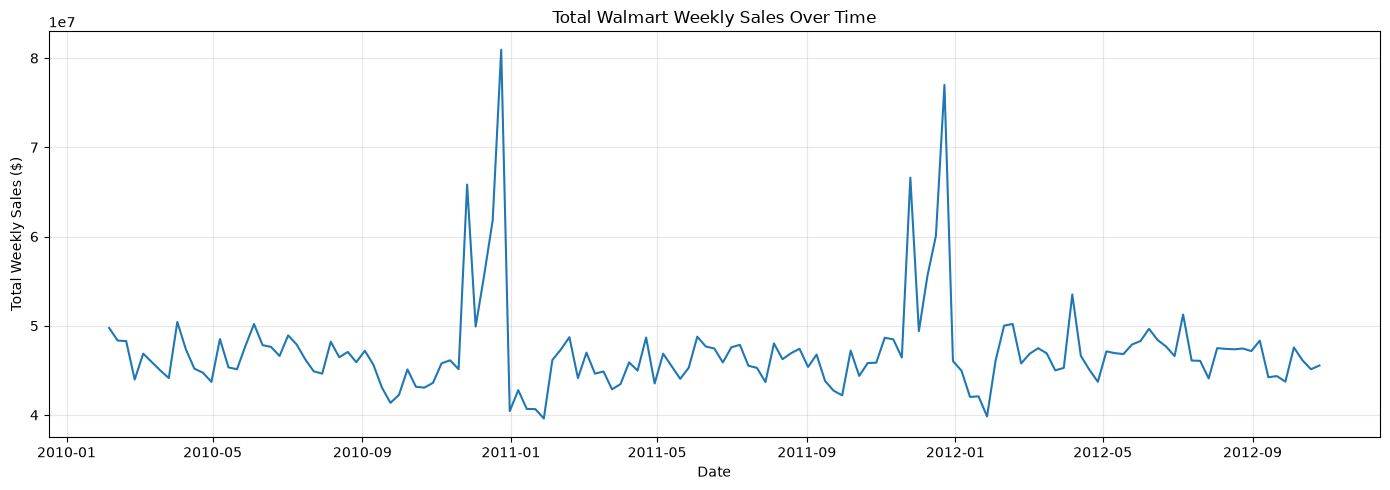

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    weekly_sales.index,
    weekly_sales.values
)

plt.title("Total Walmart Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Chart tell us**

1. No clear long-term upward trend
Most weekly totals appear to fluctuate between roughly $40 million and $50 million. Across this period, the chart does not show an obvious, sustained increase in total sales.




2. Large peaks near the end of the year
You can see sharp sales spikes around November and December in both 2010 and 2011. These may be associated with major holiday shopping periods, but we need to verify the dates before drawing that conclusion.




3. Considerable week-to-week variation
Some weeks differ substantially from neighboring weeks. This suggests that forecasting may require more than simply predicting the average weekly sales.

#### Identify the peak sales weeks

In [6]:
# Find the 10 weeks with the highest total sales
top_sales_weeks = weekly_sales.nlargest(10)

print(top_sales_weeks)

Date
2010-12-24    80931415.60
2011-12-23    76998241.31
2011-11-25    66593605.26
2010-11-26    65821003.24
2010-12-17    61820799.85
2011-12-16    60085695.94
2010-12-10    55666770.39
2011-12-09    55561147.70
2012-04-06    53502315.87
2012-07-06    51253021.88
Name: Weekly_Sales, dtype: float64


1. Late November and December dominate the top rankings.
Eight of the ten highest-sales dates fall in November or December. The repeated peaks in both 2010 and 2011 suggest a possible recurring calendar-related pattern.

2. The highest recorded week is December 24, 2010.
Total sales reached approximately $80.93 million, considerably above the usual range in your time-series plot.

3. Not every peak occurs near the year-end holidays.
April 6 and July 6, 2012 also appear in the top ten. We should investigate those dates rather than assume all large peaks have the same explanation.

Remember that these are aggregate totals across many stores and departments. A large total could reflect holiday demand, a particular mix of reporting departments, or other factors. Our results suggest patterns worth testing, not proven causes.

The official dataset description identifies four major holiday periods relevant to this forecasting problem: Super Bowl, Labor Day, Thanksgiving, and Christmas. Promotional markdowns around these periods are also an important part of the forecasting challenge

#### Verifying the holiday flags for our peak weeks

In [7]:
# Summarize total sales and holiday status for each date
weekly_details = (
    train_clean
    .groupby("Date")
    .agg(
        total_sales=("Weekly_Sales", "sum"),
        IsHoliday=("IsHoliday", "max")
    )
)

# Inspect the 10 highest-sales weeks
print(weekly_details.loc[top_sales_weeks.index])

            total_sales  IsHoliday
Date                              
2010-12-24  80931415.60      False
2011-12-23  76998241.31      False
2011-11-25  66593605.26       True
2010-11-26  65821003.24       True
2010-12-17  61820799.85      False
2011-12-16  60085695.94      False
2010-12-10  55666770.39      False
2011-12-09  55561147.70      False
2012-04-06  53502315.87      False
2012-07-06  51253021.88      False


1. The holiday flag does not capture every holiday-related sales peak.
The highest-sales weeks are December 24, 2010, and December 23, 2011, but both are marked False.

This does not necessarily mean the data is wrong. IsHoliday indicates whether a date is one of the dataset's designated holiday weeks, not whether the week is near any holiday or shopping event.

2. Sales may rise in the weeks leading up to a holiday.

Several high-sales dates occur in December but are not designated holiday weeks. This suggests that the timing of a week relative to a major shopping event may matter, beyond the binary holiday flag.

3. The Thanksgiving-related peaks are also notable.

November 26, 2010, and November 25, 2011, are marked as holidays and have high total sales. This is consistent with the possibility of Thanksgiving/Black Friday-related demand, though the aggregate data alone does not prove causation.

#### Examining sales by month

In [8]:
# Calculate average total weekly sales by month
monthly_sales = (
    weekly_sales
    .groupby(weekly_sales.index.month)
    .mean()
)

# Give month numbers readable names
monthly_sales.index = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

print(monthly_sales.round(2))

Jan    41574804.81
Feb    47393990.87
Mar    45598915.48
Apr    46204270.36
May    46427131.00
Jun    47894606.68
Jul    46428641.23
Aug    47160785.29
Sep    44520090.71
Oct    44983445.20
Nov    51626965.63
Dec    57683863.52
Name: Weekly_Sales, dtype: float64


Three findings
1. December has the highest average. At approximately $57.68 million, its average weekly sales are about 38.8% higher than January's $41.57 million.
2. November is the second-highest month. November and December both stand out from most other months, consistent with the high-sales weeks we identified earlier.
3. January has the lowest average. This may reflect a post-holiday decline, but we should not claim that explanation as proven without further analysis.

#### Visualize average weekly sales by month

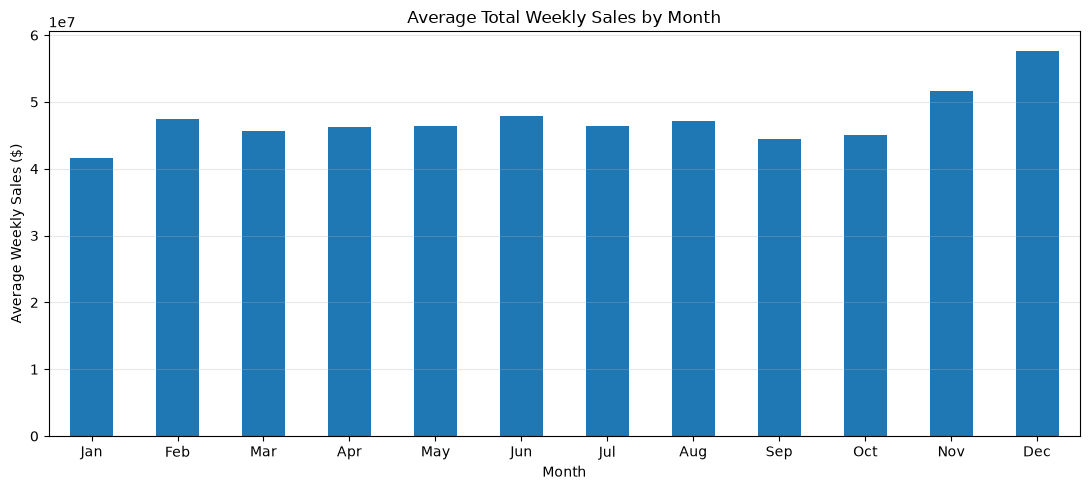

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

monthly_sales.plot(kind="bar")

plt.title("Average Total Weekly Sales by Month")
plt.xlabel("Month")
plt.ylabel("Average Weekly Sales ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Comparing monthly sales across years

In [10]:
# Create a table of average weekly sales by year and month
year_month_sales = (
    train_clean
    .assign(
        Year=train_clean["Date"].dt.year,
        Month=train_clean["Date"].dt.month
    )
    .groupby(["Year", "Month"])["Weekly_Sales"]
    .sum()
    .unstack(level="Year")
)

print(year_month_sales.round(2))

Year           2010          2011          2012
Month                                          
1               NaN  1.637040e+08  1.688945e+08
2      1.903330e+08  1.863313e+08  1.920636e+08
3      1.819198e+08  1.793564e+08  2.315097e+08
4      2.314124e+08  2.265265e+08  1.889209e+08
5      1.867109e+08  1.816482e+08  1.887665e+08
6      1.922462e+08  1.897734e+08  2.406103e+08
7      2.325801e+08  2.299114e+08  1.875095e+08
8      1.876401e+08  1.885993e+08  2.368508e+08
9      1.772679e+08  2.208477e+08  1.806455e+08
10     2.171618e+08  1.832613e+08  1.843617e+08
11     2.028534e+08  2.101624e+08           NaN
12     2.887605e+08  2.880781e+08           NaN


#### Average total sales per recorded week for each month and year.

In [11]:
# First, calculate total sales for each recorded week
weekly_details = (
    train_clean
    .groupby("Date")
    .agg(
        total_sales=("Weekly_Sales", "sum"),
        Year=("Date", lambda x: x.iloc[0].year),
        Month=("Date", lambda x: x.iloc[0].month)
    )
)

# Then calculate the average weekly total by year and month
year_month_avg = (
    weekly_details
    .groupby(["Year", "Month"])["total_sales"]
    .mean()
    .unstack(level="Year")
)

print(year_month_avg.round(2))

Year          2010         2011         2012
Month                                       
1              NaN  40925991.71  42223617.92
2      47583245.76  46582831.97  48015894.89
3      45479950.62  44839112.07  46301930.10
4      46282473.61  45305302.19  47230226.49
5      46677733.58  45412039.54  47191619.86
6      48061543.09  47443346.30  48122065.86
7      46516025.20  45982279.77  46877363.10
8      46910027.72  47149833.06  47370153.14
9      44316974.09  44169547.68  45161386.12
10     43432364.80  45815320.79  46090420.10
11     50713342.54  52540588.72          NaN
12     57752106.54  57615620.50          NaN


### 3. Examine sales by store

In [12]:
# Calculate total sales and average weekly sales for each store
store_sales = (
    train_clean
    .groupby("Store")["Weekly_Sales"]
    .agg(["sum", "mean", "median"])
    .sort_values("sum", ascending=False)
)

print(store_sales.head(10).round(2))

                sum      mean    median
Store                                  
20     3.013978e+08  29508.30  16249.78
4      2.995440e+08  29161.21  15116.81
14     2.889999e+08  28784.85  15208.80
13     2.865177e+08  27355.14  14018.46
2      2.753824e+08  26898.07  14333.53
10     2.716177e+08  26332.30  13941.43
27     2.538559e+08  24826.98  13625.95
6      2.237561e+08  21913.24  13637.84
1      2.224028e+08  21710.54  10289.38
39     2.074455e+08  21000.76  11016.42


#### Compare sales across all 45 stores

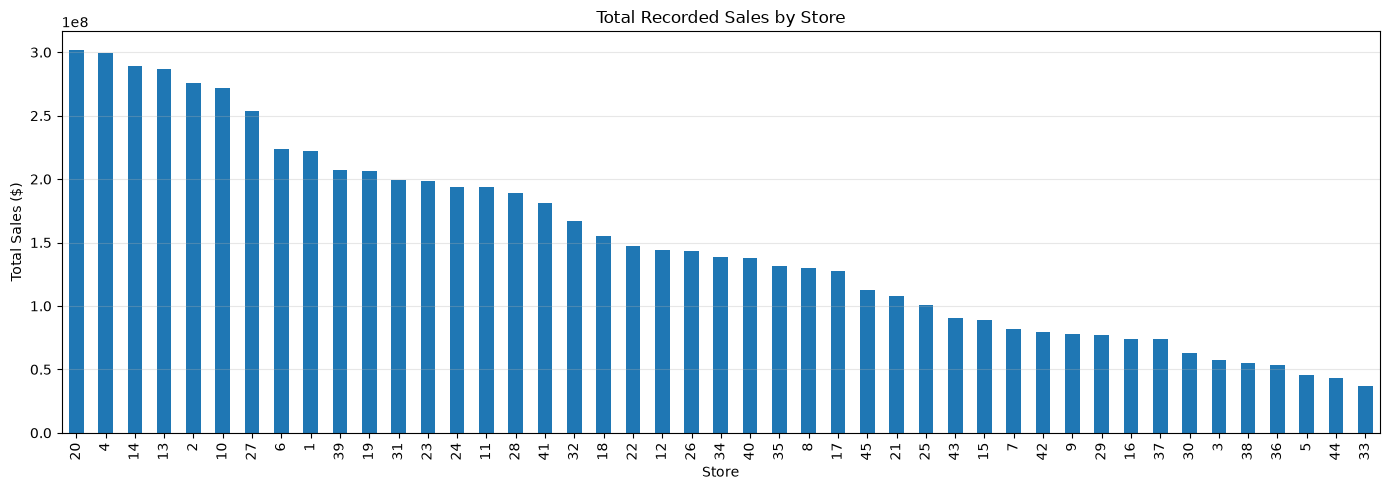

In [13]:
import matplotlib.pyplot as plt

# Sort all stores by total recorded sales
store_totals = store_sales["sum"].sort_values(ascending=False)

plt.figure(figsize=(14, 5))

store_totals.plot(kind="bar")

plt.title("Total Recorded Sales by Store")
plt.xlabel("Store")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Investigating store size and type

In [14]:
# Combine store sales totals with store information
store_analysis = (
    store_sales
    .join(stores_clean.set_index("Store"))
    .sort_values("sum", ascending=False)
)

# Display sales, store type, and store size
print(
    store_analysis[["sum", "mean", "Type", "Size"]]
    .head(10)
    .round(2)
)

                sum      mean Type    Size
Store                                     
20     3.013978e+08  29508.30    A  203742
4      2.995440e+08  29161.21    A  205863
14     2.889999e+08  28784.85    A  200898
13     2.865177e+08  27355.14    A  219622
2      2.753824e+08  26898.07    A  202307
10     2.716177e+08  26332.30    B  126512
27     2.538559e+08  24826.98    A  204184
6      2.237561e+08  21913.24    A  202505
1      2.224028e+08  21710.54    A  151315
39     2.074455e+08  21000.76    A  184109


#### Comparing average sales by store type

In [15]:
# Add store type to every sales record
sales_with_type = train_clean.merge(
    stores_clean[["Store", "Type"]],
    on="Store",
    how="left"
)

# Compare sales observations across store types
type_summary = (
    sales_with_type
    .groupby("Type")["Weekly_Sales"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print(type_summary)

       count      mean    median       std
Type                                      
A     215478  20099.57  10105.17  26423.46
B     163495  12237.08   6187.87  17203.67
C      42597   9519.53   1149.67  15985.35


1. Type A has the highest average recorded sales.

Its mean of $20,099.57 is about 64% higher than Type B's mean of $12,237.08.

2. Type C has a particularly low median.

Its median is $1,149.67, substantially below its mean of $9,519.53. This large difference suggests that its sales distribution is strongly right-skewed, potentially because some observations are much higher than others.

3. Sales vary substantially within each type.

The standard deviations are large relative to the means. This means store type alone is unlikely to explain all the variation in sales.

#### Examine the relationship between store size and sales

In [16]:
# Calculate average sales for each store
store_mean_sales = (
    train_clean
    .groupby("Store")["Weekly_Sales"]
    .mean()
    .rename("Average_Sales")
)

# Combine average sales with store size and type
store_size_analysis = (
    stores_clean
    .set_index("Store")
    .join(store_mean_sales)
)

# Measure the correlation between store size and average sales
correlation = store_size_analysis["Size"].corr(
    store_size_analysis["Average_Sales"]
)

print("Correlation between store size and average sales:",
      round(correlation, 3))

Correlation between store size and average sales: 0.807


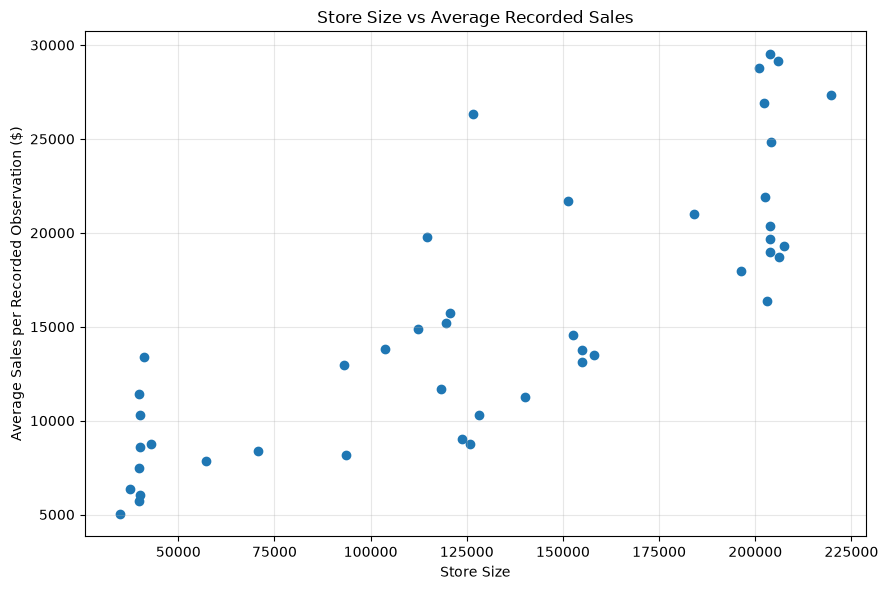

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    store_size_analysis["Size"],
    store_size_analysis["Average_Sales"]
)

plt.title("Store Size vs Average Recorded Sales")
plt.xlabel("Store Size")
plt.ylabel("Average Sales per Recorded Observation ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Investigate the distribution of weekly sales

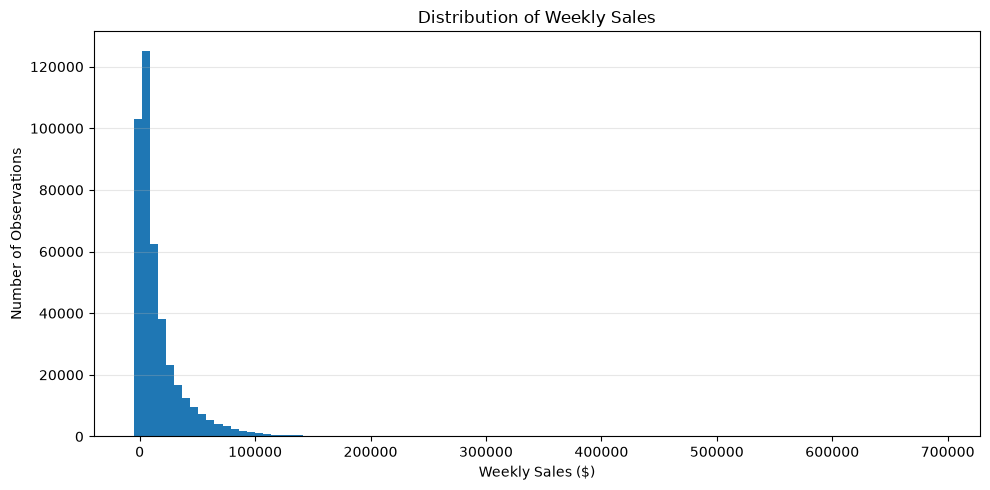

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    train_clean["Weekly_Sales"],
    bins=100
)

plt.title("Distribution of Weekly Sales")
plt.xlabel("Weekly Sales ($)")
plt.ylabel("Number of Observations")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Box plot of weekly sales

C:\Users\markr\AppData\Local\Temp\ipykernel_14648\2755683071.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


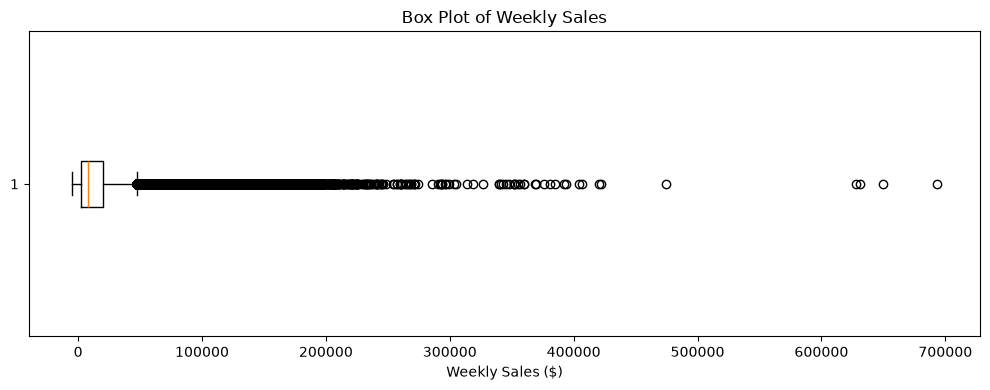

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.boxplot(
    train_clean["Weekly_Sales"],
    vert=False
)

plt.title("Box Plot of Weekly Sales")
plt.xlabel("Weekly Sales ($)")

plt.tight_layout()
plt.show()

These are store-department-week observations. High values could represent genuine sales peaks for particular departments or stores, especially during busy shopping periods. Removing them without investigation could discard useful information that our forecasting model needs to learn.

Likewise, negative weekly sales could reflect returns or accounting adjustments, but we need to investigate before assigning a cause.

#### Investigate negative sales

In [20]:
# Count negative, zero, and positive sales observations
negative_count = (train_clean["Weekly_Sales"] < 0).sum()
zero_count = (train_clean["Weekly_Sales"] == 0).sum()
positive_count = (train_clean["Weekly_Sales"] > 0).sum()

print("Negative sales:", negative_count)
print("Zero sales:", zero_count)
print("Positive sales:", positive_count)

print(
    "Percentage of negative sales:",
    round(negative_count / len(train_clean) * 100, 3),
    "%"
)

Negative sales: 1285
Zero sales: 73
Positive sales: 420212
Percentage of negative sales: 0.305 %


- Negative values are rare, but they are part of the recorded data.

- Zero sales are even rarer.

- We should not automatically remove or replace these values. Negative sales might represent returns or accounting adjustments, but the data alone does not establish their cause.

#### Inspect the negative sales records

In [21]:
# Select the 10 most negative sales observations
negative_sales = (
    train_clean[train_clean["Weekly_Sales"] < 0]
    .sort_values("Weekly_Sales")
    .head(10)
)

print(
    negative_sales[
        ["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday"]
    ]
)

        Store  Dept       Date  Weekly_Sales  IsHoliday
267730     28     6 2010-10-08      -4988.94      False
336495     35    47 2011-09-02      -3924.00      False
417801     45    47 2010-02-26      -1750.00      False
153916     16    47 2012-03-09      -1699.00      False
271300     28    32 2011-03-25      -1321.48      False
16291       2    47 2010-07-30      -1098.00      False
16295       2    47 2010-10-15      -1098.00      False
16297       2    47 2010-11-19      -1098.00      False
24830       3    32 2011-09-30      -1008.96      False
35561       4    47 2010-09-17       -898.00      False


#### Checking which departments have the most negative sales

In [22]:
# Keep only observations with negative weekly sales
negative_records = train_clean[
    train_clean["Weekly_Sales"] < 0
]

# Count negative observations by department
negative_by_dept = (
    negative_records
    .groupby("Dept")
    .size()
    .sort_values(ascending=False)
)

print("Top 10 departments by number of negative sales:")
print(negative_by_dept.head(10))

Top 10 departments by number of negative sales:
Dept
47    254
18    180
54    146
19     87
94     77
80     68
49     67
59     44
72     34
78     33
dtype: int64


#### Calculate the negative-sales rate by department

In [23]:
# Summarize total and negative observations by department
department_negative_analysis = (
    train_clean
    .assign(IsNegative=train_clean["Weekly_Sales"] < 0)
    .groupby("Dept")
    .agg(
        Total_Records=("Weekly_Sales", "size"),
        Negative_Records=("IsNegative", "sum")
    )
)

# Calculate the percentage of negative records
department_negative_analysis["Negative_Percentage"] = (
    department_negative_analysis["Negative_Records"]
    / department_negative_analysis["Total_Records"]
    * 100
)

# Show departments with the highest negative-sales rates
print(
    department_negative_analysis
    .sort_values("Negative_Percentage", ascending=False)
    .head(10)
    .round(3)
)

      Total_Records  Negative_Records  Negative_Percentage
Dept                                                      
47              646               254               39.319
78              235                33               14.043
77              150                16               10.667
18             5029               180                3.579
54             4767               146                3.063
19             4119                87                2.112
51             1394                25                1.793
49             4482                67                1.495
94             5685                77                1.354
45             1936                24                1.240


Three important findings

1. Department 47 deserves further investigation.

About 39.3% of its recorded sales are negative. That's far higher than the overall negative-sales rate of 0.305%.

2. Departments 77 and 78 also have high negative-sales rates.

However, they have relatively few observations—150 and 235 respectively. Their percentages could be sensitive to a relatively small number of records, so we shouldn't overgeneralize.

3. A negative value is not automatically a data error.

We need to understand whether these departments have unusual sales patterns, sparse observations, or some other characteristic. We don't yet have enough evidence to explain the cause.

#### Inspect the sales distribution in Department 47

In [24]:
# Separate Department 47 from all other departments
dept_47_sales = train_clean.loc[
    train_clean["Dept"] == 47, "Weekly_Sales"
]

other_dept_sales = train_clean.loc[
    train_clean["Dept"] != 47, "Weekly_Sales"
]

# Compare their distributions
comparison = pd.DataFrame({
    "Department 47": dept_47_sales.describe(),
    "All other departments": other_dept_sales.describe()
})

print(comparison.round(2))

       Department 47  All other departments
count         646.00              420924.00
mean           -7.68               16005.80
std           307.88               22719.96
min         -3924.00               -4988.94
25%           -58.00                2098.72
50%            17.98                7635.63
75%            70.00               20239.77
max          1098.00              693099.36


##### Examine Department 47's sales over time

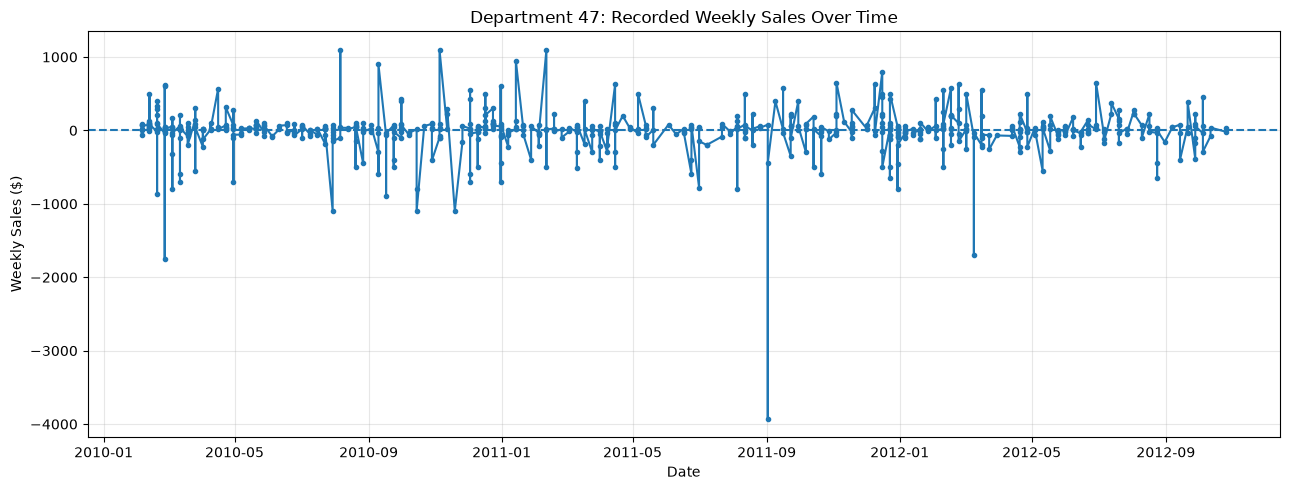

In [25]:
import matplotlib.pyplot as plt

# Extract Department 47 records and sort by date
dept_47_data = (
    train_clean[train_clean["Dept"] == 47]
    .sort_values("Date")
)

plt.figure(figsize=(13, 5))

plt.plot(
    dept_47_data["Date"],
    dept_47_data["Weekly_Sales"],
    marker="o",
    markersize=3
)

plt.axhline(0, linestyle="--")

plt.title("Department 47: Recorded Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Weekly Sales ($)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [26]:

dept_47_summary = (
    train_clean[train_clean["Dept"] == 47]
    .groupby("Store")
    .agg(
        observations=("Weekly_Sales", "count"),
        mean_sales=("Weekly_Sales", "mean"),
        negative_sales=("Weekly_Sales", lambda x: (x < 0).sum()),
        minimum_sales=("Weekly_Sales", "min")
    )
)

dept_47_summary["negative_rate_pct"] = (
    dept_47_summary["negative_sales"]
    / dept_47_summary["observations"]
    * 100
)

dept_47_summary = dept_47_summary.sort_values(
    "negative_rate_pct", ascending=False
)

dept_47_summary.round(2)


,observations,mean_sales,negative_sales,minimum_sales,negative_rate_pct
Store,,,,,
17,7,15.61,5,-259.00,71.43
23,12,-45.96,8,-298.00,66.67
31,15,-20.26,9,-224.00,60.00
12,22,-43.90,13,-598.00,59.09
34,12,-78.92,7,-598.00,58.33
24,7,-26.92,4,-109.00,57.14
35,36,-99.09,20,-3924.00,55.56
15,15,22.90,8,-179.00,53.33
10,36,-64.69,19,-798.00,52.78


In [27]:

department_negative_summary = (
    train_clean
    .groupby("Dept")
    .agg(
        observations=("Weekly_Sales", "count"),
        negative_sales=(
            "Weekly_Sales",
            lambda x: (x < 0).sum()
        ),
        mean_sales=("Weekly_Sales", "mean")
    )
)

department_negative_summary["negative_rate_pct"] = (
    department_negative_summary["negative_sales"]
    / department_negative_summary["observations"]
    * 100
)

department_negative_summary = (
    department_negative_summary
    .sort_values("negative_rate_pct", ascending=False)
)

department_negative_summary.head(15).round(2)


,observations,negative_sales,mean_sales,negative_rate_pct
Dept,,,,
47,646,254,-7.68,39.32
78,235,33,7.30,14.04
77,150,16,328.96,10.67
18,5029,180,7336.94,3.58
54,4767,146,108.31,3.06
19,4119,87,1654.82,2.11
51,1394,25,21.93,1.79
49,4482,67,8159.95,1.49
94,5685,77,33405.88,1.35


Our EDA decision

1. Preserve negative sales in the original dataset.

2. Document Departments 47, 78 and 77 as departments with unusually high negative-sales rates.

3. Avoid automatically removing outliers or converting negative sales to zero.

4. Evaluate forecasting models using metrics that remain meaningful when actual sales are zero or negative.

## EDA — Key Findings

### 1. Dataset Overview
- The training dataset contains 421,570 observations across 45 stores and 81 departments.
- Weekly sales are recorded from February 2010 to October 2012.
- The target variable is `Weekly_Sales`.

### 2. Data Quality
- No missing values or duplicate rows were found in the original training data.
- Some store–department combinations have shorter histories or gaps between recorded weeks.
- Negative sales values and extreme observations were retained for further investigation rather than automatically removed.

### 3. Sales Distribution
- Average weekly sales per store–department observation are approximately $15,981.
- The median is approximately $7,612, indicating a right-skewed distribution.
- Sales include 1,285 negative observations, representing approximately 0.3% of training records.

### 4. Time-Based Patterns
- Aggregate weekly sales show prominent peaks toward November and December.
- December has the highest average aggregate weekly sales among the calendar months examined.
- Holiday weeks have higher average recorded sales than non-holiday weeks, although this association does not establish causation.

### 5. Store-Level Findings
- Average sales vary substantially between stores.
- Store size and average recorded sales have a positive correlation of approximately 0.81 across the 45 stores.
- Store type is also associated with differences in recorded sales, although store characteristics and department mix may influence these comparisons.

### 6. Unusual Sales Observations
- Departments 47, 78 and 77 have the highest negative-sales rates in the examined department summary.
- Department 47 has 254 negative observations among 646 records, a rate of approximately 39.32%.
- Negative values and extreme observations require careful treatment during forecasting and evaluation.

### 7. Implications for Forecasting
- Forecast validation must respect chronological order to avoid data leakage.
- Store and department differences should be considered when selecting forecasting methods.
- Missing weekly intervals and short histories must be handled carefully.
- Model performance should be evaluated with metrics appropriate for the scale and distribution of weekly sales.